# 04 · Visualizations
Univariate, bivariate and multivariate charts (Matplotlib, Seaborn, Plotly). Every chart is followed by a 2–4 sentence interpretation.
Static images are also saved to `images/` for the README / presentation.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from pathlib import Path
from db_config import get_engine

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
IMG = Path("images"); IMG.mkdir(exist_ok=True)
engine = get_engine()

movies = pd.read_sql("SELECT * FROM movies", engine, parse_dates=["release_date"])
for c in ["runtime", "popularity", "vote_average"]:
    movies[c] = pd.to_numeric(movies[c], errors="coerce")
movies["release_year"] = movies["release_date"].dt.year
movies["budget_m"]  = movies["budget"].replace(0, np.nan) / 1e6     # 0 = unknown
movies["revenue_m"] = movies["revenue"].replace(0, np.nan) / 1e6
mg = pd.read_sql("SELECT mg.movie_id, g.genre_name FROM movie_genres mg JOIN genres g USING (genre_id)", engine)
movie_genre = mg.merge(movies, on="movie_id")        # one row per movie x genre

def save(name):
    plt.tight_layout(); plt.savefig(IMG / f"{name}.png", dpi=120, bbox_inches="tight"); plt.show()

# Part A – Univariate

## A1. Distribution of movie budgets

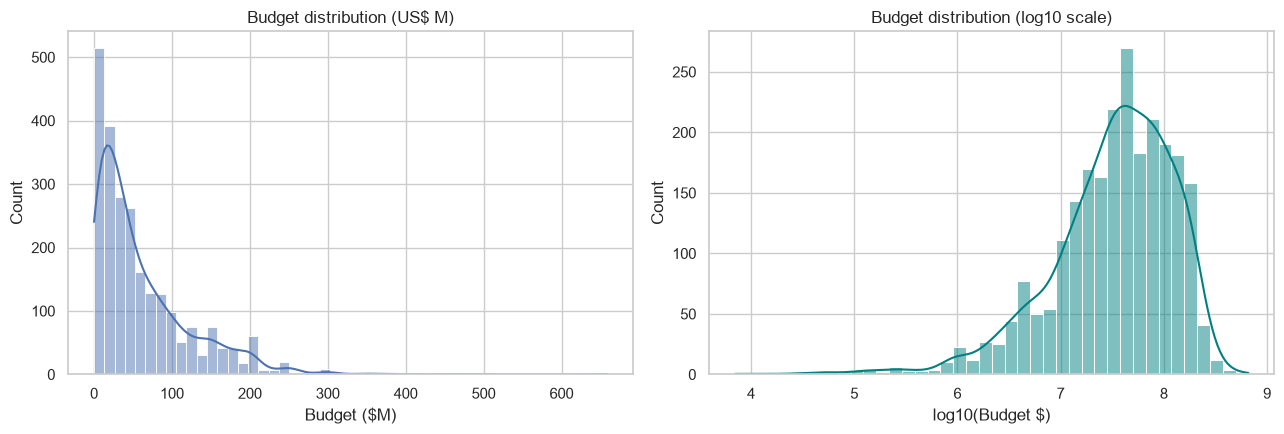

Median budget $40.0M | mean $60.8M


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(movies["budget_m"].dropna(), bins=50, kde=True, ax=ax[0])
ax[0].set(title="Budget distribution (US$ M)", xlabel="Budget ($M)")
sns.histplot(np.log10(movies["budget"].replace(0, np.nan).dropna()), bins=40, kde=True, ax=ax[1], color="teal")
ax[1].set(title="Budget distribution (log10 scale)", xlabel="log10(Budget $)")
save("A1_budget_distribution")
print(f"Median budget ${movies.budget_m.median():,.1f}M | mean ${movies.budget_m.mean():,.1f}M")

**Interpretation:** budgets are strongly right-skewed – median $40M vs mean $60.8M – because a thin tail of blockbusters pulls the mean up. On a log scale the distribution is roughly bell-shaped, so log-transforms suit modelling. Business use: benchmark a new project against the *median*, not the mean.

## A2. Distribution of runtimes

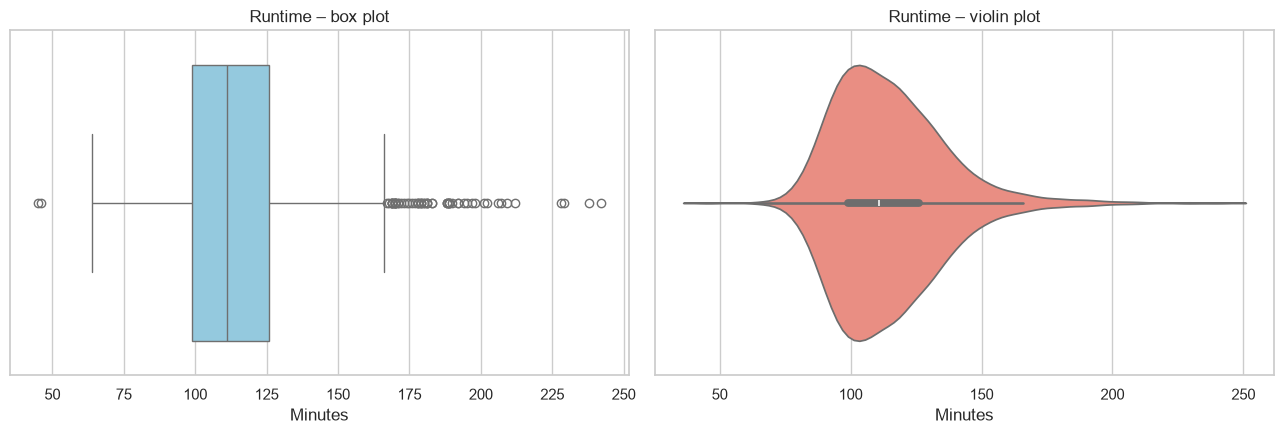

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=movies["runtime"], ax=ax[0], color="skyblue"); ax[0].set(title="Runtime – box plot", xlabel="Minutes")
sns.violinplot(x=movies["runtime"], ax=ax[1], color="salmon"); ax[1].set(title="Runtime – violin plot", xlabel="Minutes")
save("A2_runtime_distribution")

**Interpretation:** runtimes cluster tightly – half of all films run 99–126 minutes (median 111). The few outliers are epics above ~166 minutes (notebook 03, Q6). The tight band reflects theatrical scheduling economics.

## A3. Distribution of ratings (vote_average)

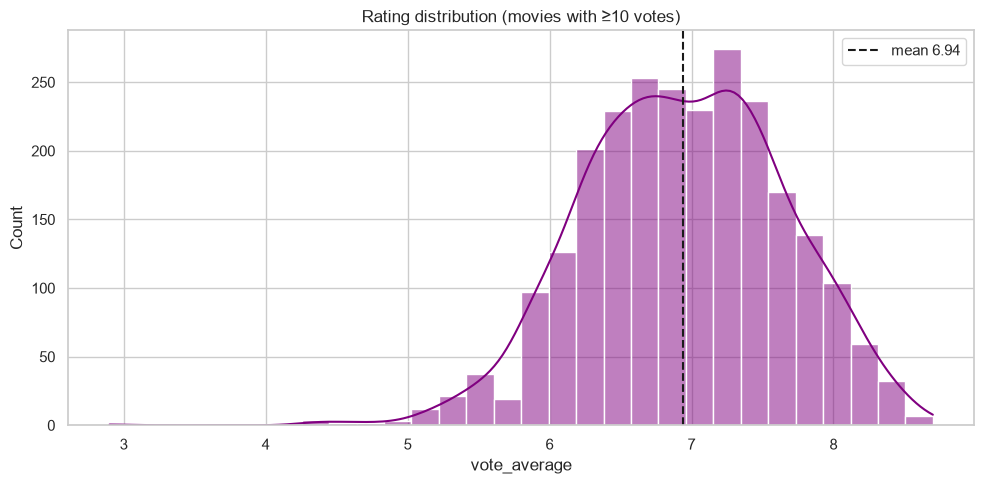

In [4]:
rated = movies[movies["vote_count"] >= 10]            # ignore titles with too few votes
ax = sns.histplot(rated["vote_average"], bins=30, kde=True, color="purple")
ax.axvline(rated["vote_average"].mean(), ls="--", c="k", label=f"mean {rated.vote_average.mean():.2f}")
ax.set(title="Rating distribution (movies with ≥10 votes)", xlabel="vote_average"); ax.legend()
save("A3_rating_distribution")

**Interpretation:** ratings are concentrated around the mean of 6.94 with few extremes, so a rating above ~7.5 is genuinely exceptional. Titles with fewer than 10 votes were excluded because their averages are unreliable.

## A4. Count of movies per genre

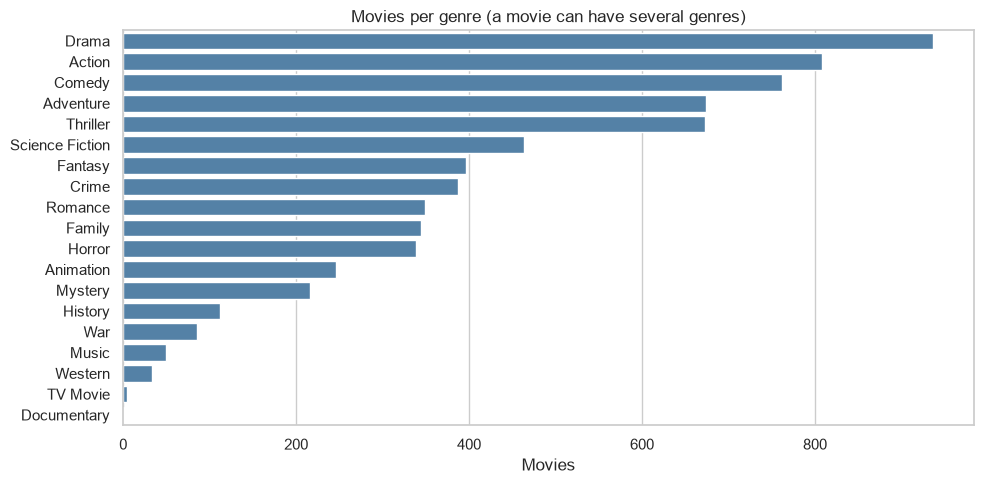

In [5]:
order = movie_genre["genre_name"].value_counts().index
ax = sns.countplot(data=movie_genre, y="genre_name", order=order, color="steelblue")
ax.set(title="Movies per genre (a movie can have several genres)", xlabel="Movies", ylabel="")
save("A4_movies_per_genre")

**Interpretation:** Drama (937), Action (808) and Comedy (762) dominate, while Documentary and TV Movie have only a handful of titles. Averages for small genres are unstable, which is why genre comparisons use a minimum sample size (SQL Q9).

# Part B – Bivariate

## B1. Budget vs revenue (with trend line)

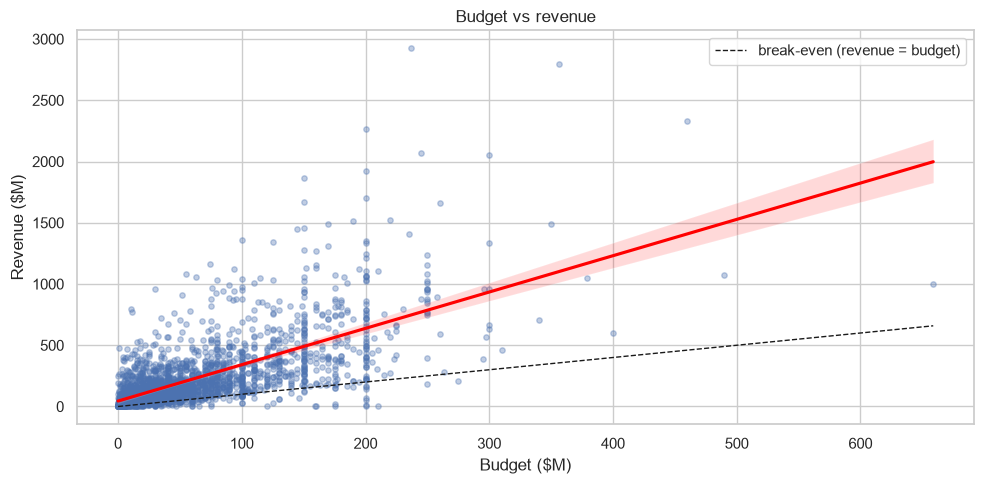

Correlation budget-revenue: 0.68 (n=2370)


In [6]:
fin = movies.dropna(subset=["budget_m", "revenue_m"])
ax = sns.regplot(data=fin, x="budget_m", y="revenue_m", scatter_kws={"alpha": .35, "s": 15}, line_kws={"color": "red"})
ax.plot([0, fin.budget_m.max()], [0, fin.budget_m.max()], "k--", lw=1, label="break-even (revenue = budget)")
ax.set(title="Budget vs revenue", xlabel="Budget ($M)", ylabel="Revenue ($M)"); ax.legend()
save("B1_budget_vs_revenue")
print(f"Correlation budget-revenue: {fin.budget_m.corr(fin.revenue_m):.2f} (n={len(fin)})")

**Interpretation:** revenue rises with budget (r = 0.68, n = 2,370), but the spread widens sharply at higher budgets – big spend raises the ceiling *and* the risk. Points below the dashed break-even line lost money at the box office.

## B2. Popularity vs vote count

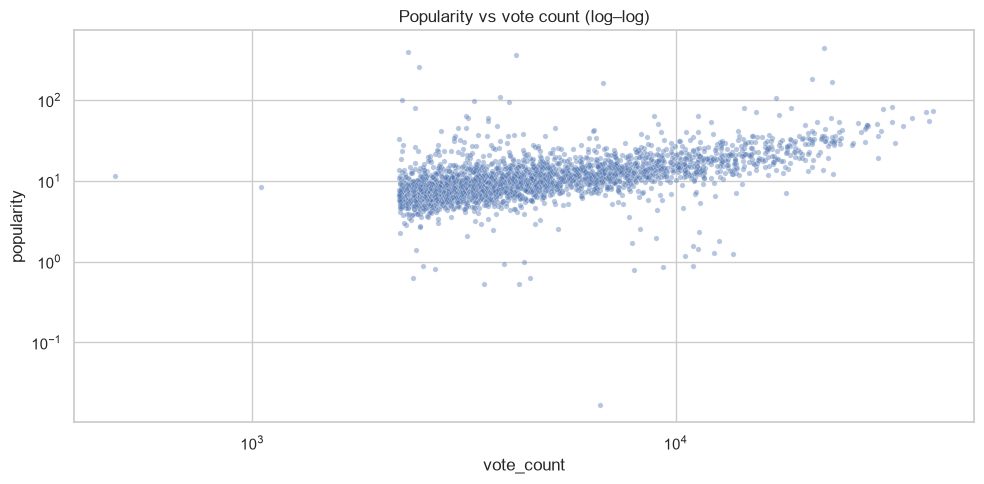

In [7]:
d = movies[(movies.vote_count > 0) & (movies.popularity > 0)]
ax = sns.scatterplot(data=d, x="vote_count", y="popularity", alpha=.4, s=15)
ax.set(xscale="log", yscale="log", title="Popularity vs vote count (log–log)")
save("B2_popularity_vs_votes")

**Interpretation:** the two metrics move together moderately (r = 0.58 on a log scale), with a wide band. Points far above the band are trending titles; points below are older well-known films (notebook 03, Q10).

## B3. Average rating by genre

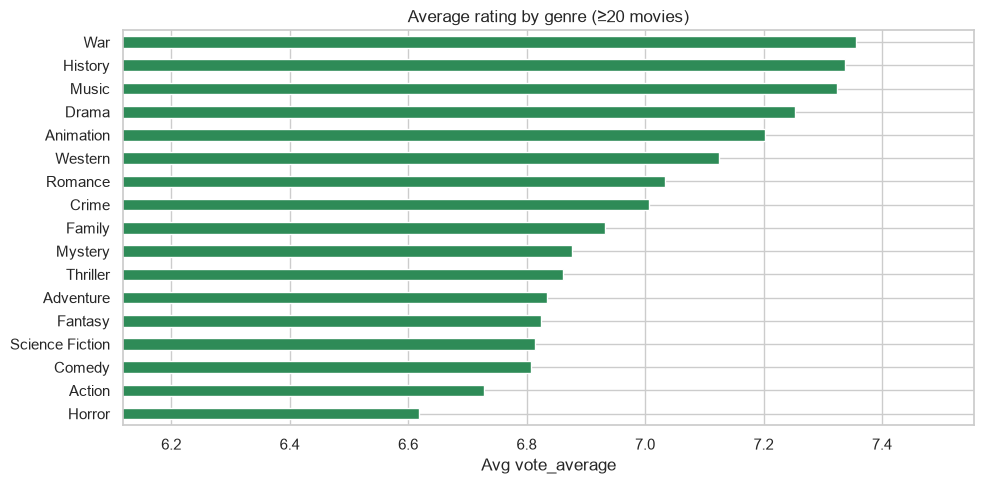

In [8]:
gr = (movie_genre[movie_genre.vote_count >= 10].groupby("genre_name")["vote_average"]
      .agg(["mean", "count"]).query("count >= 20").sort_values("mean"))
ax = gr["mean"].plot.barh(color="seagreen")
ax.set(title="Average rating by genre (≥20 movies)", xlabel="Avg vote_average", ylabel="")
ax.set_xlim(gr["mean"].min() - .5, gr["mean"].max() + .2)
save("B3_rating_by_genre")

**Interpretation:** War (7.36), History (7.34) and Music (7.32) rate highest; Horror (6.62) and Action (6.73) rate lowest – yet Horror has the best ROI and Action high revenue. The whole range is under 0.8 points, so quality and commercial return should be tracked as separate KPIs.

## B4. Movies released per year

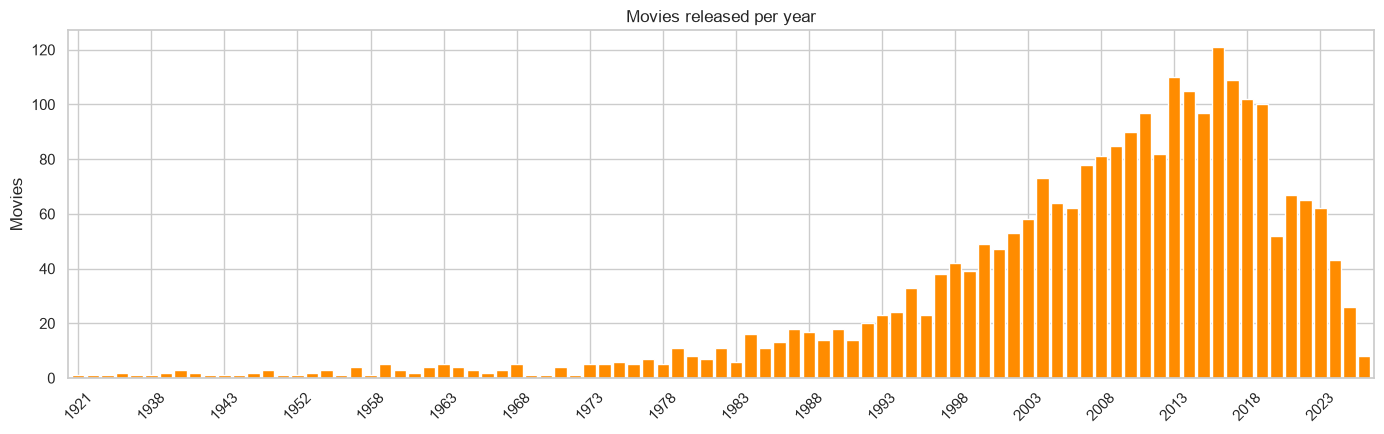

In [9]:
per_year = movies.dropna(subset=["release_year"]).groupby("release_year").size()
ax = per_year.plot.bar(figsize=(14, 4.5), color="darkorange", width=.85)
ax.set(title="Movies released per year", xlabel="", ylabel="Movies")
ax.set_xticks(range(0, len(per_year), 5)); ax.set_xticklabels(per_year.index[::5].astype(int), rotation=45)
save("B4_movies_per_year")

**Interpretation:** output grows strongly from the 1990s to a 2016 peak (121 films), then drops after 2019. The fall reflects the pandemic and an incomplete snapshot for recent years rather than a real collapse, so trends should use complete years only.

# Part C – Multivariate

## C1. Correlation heatmap of numeric features

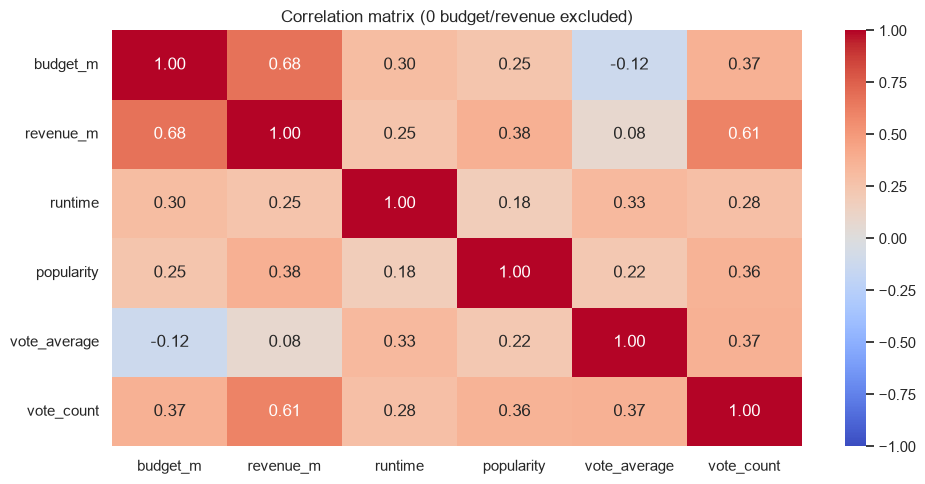

In [10]:
num = movies[["budget_m", "revenue_m", "runtime", "popularity", "vote_average", "vote_count"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (0 budget/revenue excluded)")
save("C1_correlation_heatmap")

**Interpretation:** budget–revenue (0.68) and revenue–vote_count (0.61) are the strongest links – bigger films earn more and get more attention. Rating is almost unrelated to money (−0.12 with budget, 0.08 with revenue), confirming quality and commercial scale are different dimensions.

## C2. Budget vs revenue by genre, sized by popularity (interactive)

In [11]:
top_genres = movie_genre["genre_name"].value_counts().head(6).index
plot_df = movie_genre[movie_genre.genre_name.isin(top_genres)].dropna(subset=["budget_m", "revenue_m"])
fig = px.scatter(plot_df, x="budget_m", y="revenue_m", color="genre_name", size="popularity",
                 hover_name="title", log_x=True, log_y=True, opacity=.6,
                 labels={"budget_m": "Budget ($M, log)", "revenue_m": "Revenue ($M, log)", "genre_name": "Genre"},
                 title="Budget vs revenue by genre (bubble = popularity)")
fig.show()

**Interpretation:** genres occupy different budget bands – action/adventure sit at the high-budget end while drama/horror sit lower. Within each genre, the most popular (largest) bubbles are usually the highest-revenue films. Hover over any bubble to see the title.

## C3. Average rating by genre across decades

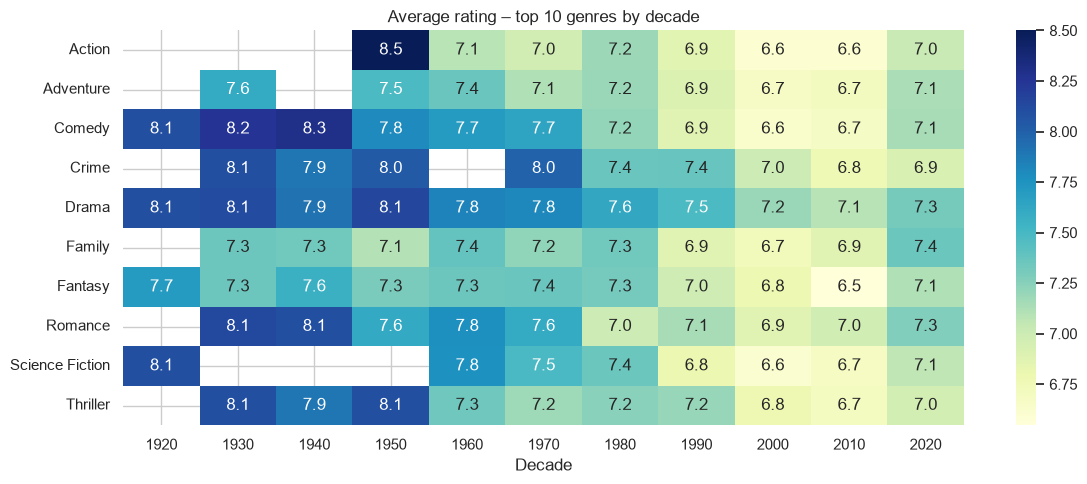

In [12]:
mgd = movie_genre.dropna(subset=["release_year"]).assign(decade=lambda d: (d.release_year // 10 * 10).astype(int))
pivot = mgd[mgd.genre_name.isin(movie_genre.genre_name.value_counts().head(10).index)] \
    .pivot_table(index="genre_name", columns="decade", values="vote_average", aggfunc="mean")
plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average rating – top 10 genres by decade"); plt.xlabel("Decade"); plt.ylabel("")
save("C3_rating_genre_decade")

**Interpretation:** the heatmap shows whether genre quality has drifted over time. Older decades often rate higher because only well-remembered classics survive in the data (survivorship bias). Compare within a decade when benchmarking genres.

## Visualization summary
- Money variables are skewed → use medians and log scales.
- Budget drives revenue potential but also risk; ratings are largely independent of budget.
- Genre mix and popularity patterns guide acquisition (what to buy) and marketing (what to push now).